# Multi-worker sign-policy rollouts and trajectory movie

Use this notebook from the `floridyn_portable` folder with the Python environment containing its requirements. For notebook/movie support, install once in that environment: `python -m pip install -r requirements-notebook.txt`.

By default this notebook **loads the latest completed experiment**, so you can immediately inspect the demo already run. To launch new rollouts, set `RUN_NEW_ROLLOUTS = True`, choose `WORKERS` and `ROLLOUTS`, and run the cells in order. The notebook launches `sign_policy_demo.py` in a separate Python process; the process pool is created by that importable script, not inside a notebook cell. Existing jobs and original OFF case files are not modified.

The movie animates **turbine headings, wind direction, yaw misalignment, and simulated total farm power**. RL rollouts do not export spatial flow fields, so this is a trajectory movie, not a wake/CFD velocity-field movie. More workers run independent simulations concurrently; they do not split the timesteps of one simulation.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
from datetime import datetime
import uuid
import numpy as np
import pandas as pd
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Video

# Usually the notebook kernel starts in this notebook's directory.
candidates = [Path.cwd(), Path.cwd() / "floridyn_portable", *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "fdynsim.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set ROOT to the folder containing fdynsim.py, or start Jupyter in floridyn_portable.")
BASE_CASE = ROOT / "OFF/02_Examples_and_Cases/02_Example_Cases/001_two_turbines_yaw_step_floris.yaml"
print("Package:", ROOT)
print("Python used for worker subprocesses:", sys.executable)

Package: /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable
Python used for worker subprocesses: /project2/ghanem_226/cwarme/Wind Turbines/.venv/bin/python


## Controls

Set any positive worker count supported by your machine/HPC allocation. At most `min(WORKERS, ROLLOUTS)` workers can be busy. Use at least as many rollouts as workers to exercise them all. `THREADS_PER_WORKER=1` limits numerical-library threads in the new subprocesses only.

Set `USE_CASE_WIND=False` to use the two functions below instead of the case's wind tables. They are sampled on the simulation time grid. `N_OP` is observation points **per turbine**, inherited from the base YAML if set to `None`. The notebook writes any overrides into a separate case copy only when starting new runs. `EXPERIMENT_DIR` selects a saved experiment folder when new runs are disabled; `None` chooses the latest completed one.

In [2]:
RUN_NEW_ROLLOUTS = True
WORKERS = 16
ROLLOUTS = 1
DURATION = 1600
DT = 4.0
ANGULAR_SPEED = 0.3             # deg/s; action = ANGULAR_SPEED * sign(W_theta - heading)
LAMBDA = 0.01
N_OP = 200                     # Per turbine; None preserves base YAML value
THREADS_PER_WORKER = 1
KEEP_NATIVE_RESULTS = False    # True retains native measurement/control CSVs
USE_CASE_WIND = True
EXPERIMENT_DIR = None          # Or Path("rl_runs/sign_test_...")
ROLLOUT_INDEX = 0              # Which saved trajectory to plot/animate
MOVIE_FPS = 10
MOVIE_FRAME_STRIDE = 1         # 1 uses every saved simulation sample
MAKE_MOVIE = True

# Used only when USE_CASE_WIND=False. t is a NumPy array of seconds.
def wind_speed(t):
    return np.full_like(t, 8.0, dtype=float)

def wind_direction(t):
    return 270.0 - 500 * np.clip(t / 1200.0, 0.0, 1.0)


In [3]:
if WORKERS < 1 or ROLLOUTS < 1 or THREADS_PER_WORKER < 1:
    raise ValueError("Use positive worker, rollout and thread counts.")
if DT <= 0 or DURATION <= 0 or not np.isclose(DURATION / DT, round(DURATION / DT)):
    raise ValueError("DURATION must be a positive integer multiple of DT.")
if N_OP is not None and (int(N_OP) != N_OP or N_OP < 2):
    raise ValueError("N_OP must be an integer >= 2, or None.")
planned_settings = yaml.safe_load(BASE_CASE.read_text())
start = float(planned_settings["sim"]["sim"]["time start"])
planned_times = start + np.arange(round(DURATION / DT) + 1) * DT
ambient = planned_settings["ambient"]["flow_field"]
if USE_CASE_WIND:
    planned_W = np.interp(planned_times, ambient.get("wind_speeds_t", [start]), ambient["wind_speeds"])
    planned_W_theta = np.interp(planned_times, ambient.get("wind_directions_t", [start]), ambient["wind_directions"])
else:
    planned_W = np.broadcast_to(np.asarray(wind_speed(planned_times), dtype=float), planned_times.shape).copy()
    planned_W_theta = np.broadcast_to(np.asarray(wind_direction(planned_times), dtype=float), planned_times.shape).copy()
if not np.isfinite(planned_W).all() or not np.isfinite(planned_W_theta).all() or np.any(planned_W <= 0):
    raise ValueError("Wind samples must be finite and speeds positive.")
ambient.update(wind_speeds=planned_W.tolist(), wind_speeds_t=planned_times.tolist(),
               wind_directions=planned_W_theta.tolist(), wind_directions_t=planned_times.tolist())
if N_OP is not None:
    planned_settings["solver"]["settings"]["n_op"] = int(N_OP)
print("Settings for a NEW run:")
print(f"{WORKERS} workers; {ROLLOUTS} rollouts; {len(planned_times)-1} transitions per turbine")
print("Observation points per turbine:", planned_settings["solver"]["settings"]["n_op"])
print(f"Wind speed: {planned_W.min():.3f}–{planned_W.max():.3f} m/s")
print(f"Wind direction: {planned_W_theta[0]:.3f} → {planned_W_theta[-1]:.3f} degrees")
if not RUN_NEW_ROLLOUTS:
    print("New simulations disabled: plots below use SAVED results, not these planned settings.")

Settings for a NEW run:
16 workers; 1 rollouts; 400 transitions per turbine
Observation points per turbine: 200
Wind speed: 8.000–8.000 m/s
Wind direction: 270.000 → 230.000 degrees


## Launch workers or select completed results

The generated notebook case is passed through `sign_policy_demo.py --case ...`. Each worker then reuses its own YAML, while FDynSim handles the native simulation. Identical deterministic policies and wind inputs yield identical trajectories across rollouts; worker count changes throughput, not the simulated scenario.

In [4]:
if RUN_NEW_ROLLOUTS:
    case_folder = ROOT / "rl_runs" / "notebook_cases"
    case_folder.mkdir(parents=True, exist_ok=True)
    session_case = case_folder / f"case_{datetime.now():%Y%m%d_%H%M%S}_{uuid.uuid4().hex[:8]}.yaml"
    session_case.write_text(yaml.safe_dump(planned_settings, sort_keys=False))
    command = [sys.executable, "-u", str(ROOT / "sign_policy_demo.py"),
               "--case", str(session_case), "--duration", str(DURATION), "--dt", str(DT),
               "--angular-speed", str(ANGULAR_SPEED), "--lambda", str(LAMBDA),
               "--workers", str(WORKERS), "--rollouts", str(ROLLOUTS)]
    if KEEP_NATIVE_RESULTS:
        command.append("--keep-results")
    worker_env = os.environ.copy()
    for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        worker_env[variable] = str(THREADS_PER_WORKER)
    print("Running:", " ".join(command), flush=True)
    completed = subprocess.run(command, cwd=ROOT, env=worker_env, text=True,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(completed.stdout)
    completed.check_returncode()
    experiment_dir = Path(next(line[len("Results: "):] for line in reversed(completed.stdout.splitlines())
                               if line.startswith("Results: ")))
elif EXPERIMENT_DIR is not None:
    experiment_dir = Path(EXPERIMENT_DIR).expanduser()
    if not experiment_dir.is_absolute():
        experiment_dir = ROOT / experiment_dir
    experiment_dir = experiment_dir.resolve()
else:
    experiments = [p for p in (ROOT / "rl_runs").glob("sign_test_*") if any(p.glob("trajectory_*.npz"))]
    if not experiments:
        raise FileNotFoundError("No completed results found. Set RUN_NEW_ROLLOUTS=True.")
    experiment_dir = max(experiments, key=lambda p: p.name)
trajectory_files = sorted(experiment_dir.glob("trajectory_*.npz"))
if not 0 <= ROLLOUT_INDEX < len(trajectory_files):
    raise IndexError(f"ROLLOUT_INDEX must be between 0 and {len(trajectory_files)-1}.")
trajectory_file = trajectory_files[ROLLOUT_INDEX]
print("Selected saved trajectory:", trajectory_file)

Running: /project2/ghanem_226/cwarme/Wind Turbines/.venv/bin/python -u /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/sign_policy_demo.py --case /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/rl_runs/notebook_cases/case_20261106_144213_f11d3aac.yaml --duration 1600 --dt 4.0 --angular-speed 0.3 --lambda 0.01 --workers 16 --rollouts 1
Rollout 0: energy=10.282748 MWh; trajectory=/project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/rl_runs/sign_test_20261106_144214_09da1983/trajectory_00000.npz
Results: /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/rl_runs/sign_test_20261106_144214_09da1983

Selected saved trajectory: /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/rl_runs/sign_test_20261106_144214_09da1983/trajectory_00000.npz


Saved run: 6 turbines; 0–1600 s; 400 transitions each
Saved observation-point count: 200
Saved wind direction: 270.000 → 230.000 degrees
Farm energy: 10.282748 MWh
Terminal reward: 370178917.9666239


,time_s,wind_m_s,wind_from_deg,farm_power_MW
0,0.0,8.0,270.000000,13.353292
1,4.0,8.0,269.866667,13.353292
2,8.0,8.0,269.733333,13.353260
3,12.0,8.0,269.600000,13.353200
4,16.0,8.0,269.466667,13.353157


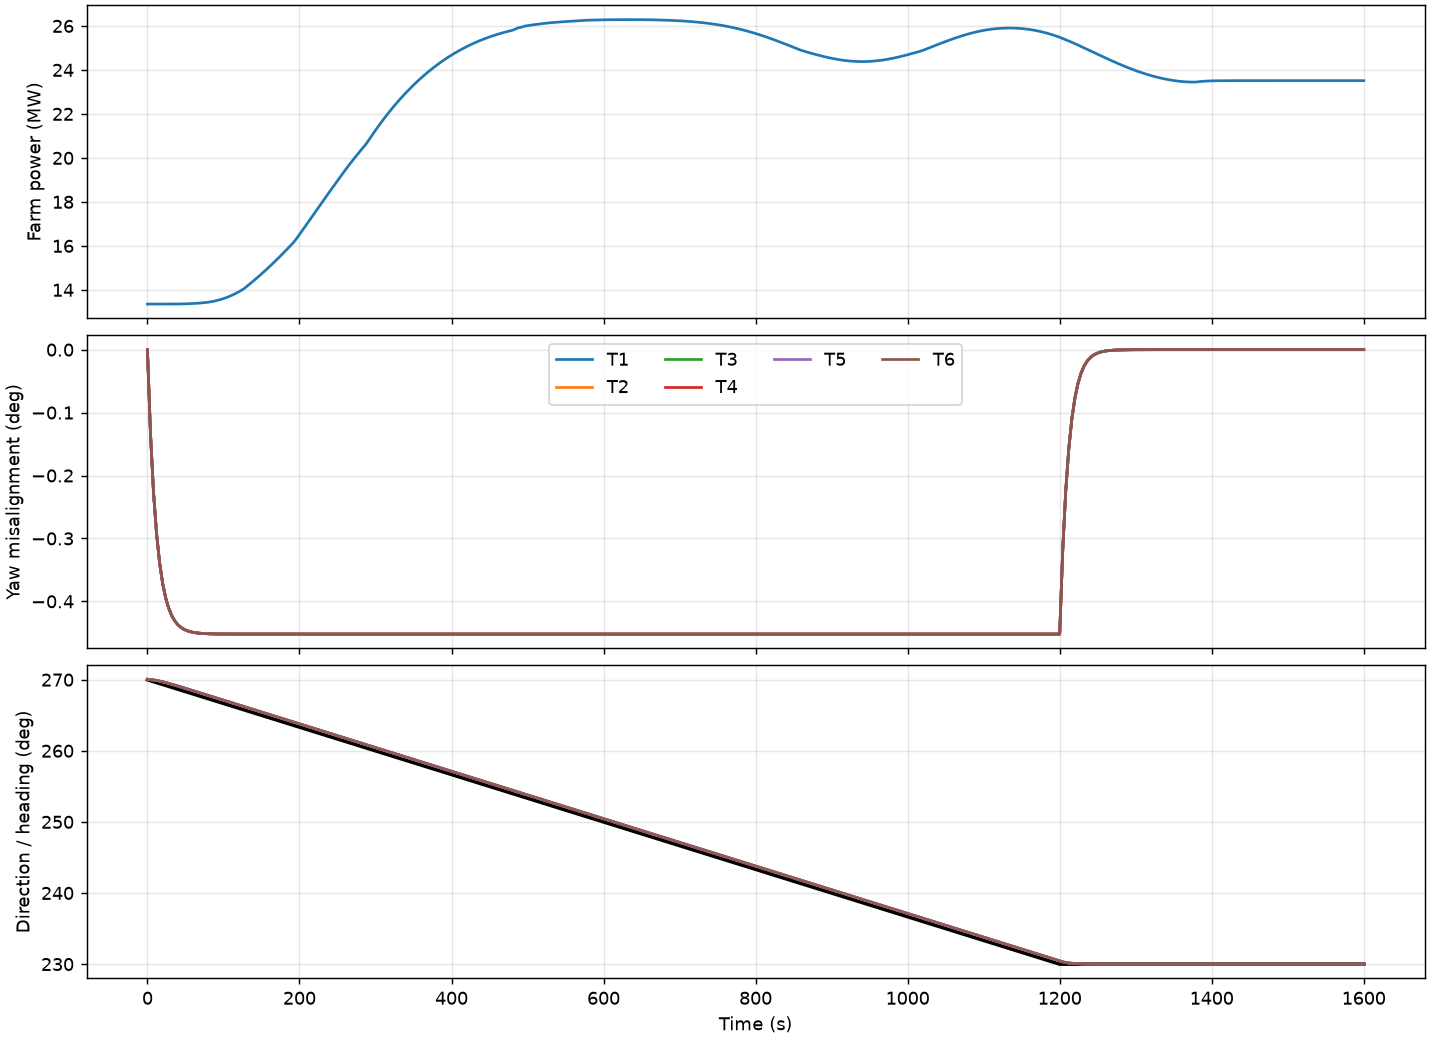

In [5]:
with np.load(trajectory_file) as archive:
    saved = {key: archive[key].copy() for key in archive.files}
times = saved["times"]
headings = saved["headings"]
farm_power = saved["farm_power"]
# Recover ALL N+1 wind samples from the actual saved states, including final next_state.
W = np.r_[saved["states"][0, :, 0], saved["next_states"][0, -1, 0]]
W_theta = np.r_[saved["states"][0, :, 1], saved["next_states"][0, -1, 1]]
yaw = (W_theta[:, None] - headings + 180.0) % 360.0 - 180.0
worker_cases = sorted(experiment_dir.glob("worker_*/case.yaml"))
if not worker_cases:
    raise FileNotFoundError("Keep a worker case.yaml with the trajectory to recover its turbine layout.")
saved_case = yaml.safe_load(worker_cases[0].read_text())
farm = saved_case["wind_farm"]["farm"]
n_turbines = headings.shape[1]
assert len(farm["layout_x"]) == n_turbines
D = float(farm["diameter"][0]) if "diameter" in farm else float(saved_case["turbine"][farm["turbine_type"][0]]["rotor_diameter"])
factor = D if farm["unit"][0] == "D" else 1.0
x = np.asarray(farm["layout_x"]) * factor / D
y = np.asarray(farm["layout_y"]) * factor / D
rotor_diameters = np.array([saved_case["turbine"][name]["rotor_diameter"] for name in farm["turbine_type"]]) / D
print(f"Saved run: {n_turbines} turbines; {times[0]:g}–{times[-1]:g} s; {len(times)-1} transitions each")
print("Saved observation-point count:", saved_case["solver"]["settings"]["n_op"])
print(f"Saved wind direction: {W_theta[0]:.3f} → {W_theta[-1]:.3f} degrees")
print(f"Farm energy: {float(saved['energy']) / 3.6e9:.6f} MWh")
print("Terminal reward:", saved["R"][-1])
display(pd.DataFrame({"time_s": times, "wind_m_s": W, "wind_from_deg": W_theta,
                      "farm_power_MW": farm_power / 1e6}).head())
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout="constrained")
axes[0].plot(times, farm_power / 1e6)
axes[0].set_ylabel("Farm power (MW)")
for i in range(n_turbines):
    axes[1].plot(times, yaw[:, i], label=f"T{i+1}")
axes[1].set_ylabel("Yaw misalignment (deg)")
axes[1].legend(ncol=min(n_turbines, 4))
axes[2].plot(times, W_theta, label="Wind direction", color="black", linewidth=2)
for i in range(n_turbines):
    axes[2].plot(times, headings[:, i], label=f"Heading T{i+1}", alpha=0.7)
axes[2].set_ylabel("Direction / heading (deg)")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.grid(alpha=0.3)
summary_path = trajectory_file.with_name(trajectory_file.stem + "_summary.png")
fig.savefig(summary_path, dpi=130)
plt.close(fig)
display(Image(filename=str(summary_path)))

## Trajectory movie

Each frame shows one saved simulation sample. Rotor lines and colored arrows show turbine headings; the blue arrow points in the **wind's direction of travel** (opposite its meteorological direction-from angle). The power and yaw panels use simulated results and a moving time cursor. This movie does **not** draw estimated wake fields. `MOVIE_FRAME_STRIDE=1` uses all samples; playback is faster than physical time according to the chosen FPS. The physical `farm_power` array is used for plotting, not `R`, whose final entry was replaced by the terminal energy reward.

The resulting MP4 is saved next to the selected NPZ and embedded below. It can be regenerated without rerunning any simulation.

In [6]:
if MAKE_MOVIE:
    try:
        import imageio_ffmpeg
    except ImportError as exc:
        raise ImportError("Install requirements-notebook.txt in this kernel's environment, then rerun this cell.") from exc
    from matplotlib.animation import FFMpegWriter
    from matplotlib.collections import LineCollection
    if MOVIE_FPS <= 0 or int(MOVIE_FRAME_STRIDE) != MOVIE_FRAME_STRIDE or MOVIE_FRAME_STRIDE < 1:
        raise ValueError("Use a positive FPS and positive integer frame stride.")
    frames = list(range(0, len(times), int(MOVIE_FRAME_STRIDE)))
    if frames[-1] != len(times)-1:
        frames.append(len(times)-1)
    colors = [plt.get_cmap("tab10")(i % 10) for i in range(n_turbines)]
    fig = plt.figure(figsize=(12, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2, width_ratios=(1.35, 1))
    map_ax = fig.add_subplot(grid[:, 0])
    power_ax = fig.add_subplot(grid[0, 1])
    yaw_ax = fig.add_subplot(grid[1, 1], sharex=power_ax)
    map_ax.set(xlim=(x.min()-2, x.max()+2), ylim=(y.min()-2, y.max()+3),
               xlabel="x / reference D", ylabel="y / reference D", title="Turbine layout and headings")
    map_ax.set_aspect("equal", adjustable="box")
    map_ax.grid(alpha=0.2)
    map_ax.scatter(x, y, c=colors, s=22)
    for i in range(n_turbines):
        map_ax.text(x[i], y[i]+0.75, f"T{i+1}", ha="center", color=colors[i])
    rotors = LineCollection([], colors=colors, linewidths=3)
    map_ax.add_collection(rotors)
    facing = map_ax.quiver(x, y, np.zeros(n_turbines), np.zeros(n_turbines), color=colors,
                           angles="xy", scale_units="xy", scale=1, width=0.008)
    wind_arrow = map_ax.quiver([x.min()-0.8], [y.max()+1.8], [0], [0], color="tab:blue",
                               angles="xy", scale_units="xy", scale=1, width=0.01)
    map_ax.text(x.min()-1.3, y.max()+2.45, "Blue arrow: wind travel", color="tab:blue", fontsize=9)
    map_ax.text(0.02, 0.02, "Colored arrows: rotor facing direction", transform=map_ax.transAxes, fontsize=9)
    power_ax.plot(times, farm_power/1e6, color="black")
    power_ax.set(ylabel="Farm power (MW)", xlim=(times[0], times[-1]))
    power_cursor = power_ax.axvline(times[0], color="tab:red", alpha=0.7)
    power_dot, = power_ax.plot([], [], "o", color="tab:red")
    for i in range(n_turbines):
        yaw_ax.plot(times, yaw[:, i], color=colors[i], label=f"T{i+1}")
    yaw_ax.set(xlabel="Simulation time (s)", ylabel="Yaw misalignment (deg)")
    yaw_ax.legend(ncol=min(n_turbines, 3), fontsize=8)
    yaw_cursor = yaw_ax.axvline(times[0], color="tab:red", alpha=0.7)
    power_ax.grid(alpha=0.3)
    yaw_ax.grid(alpha=0.3)
    title = fig.suptitle("")
    movie_path = trajectory_file.with_name(trajectory_file.stem + "_movie.mp4")
    with matplotlib.rc_context({"animation.ffmpeg_path": imageio_ffmpeg.get_ffmpeg_exe()}):
        writer = FFMpegWriter(fps=MOVIE_FPS, codec="libx264",
                              extra_args=["-pix_fmt", "yuv420p", "-movflags", "+faststart"])
        with writer.saving(fig, str(movie_path), dpi=100):
            for k in frames:
                angle = np.deg2rad(headings[k])
                front = np.column_stack((np.sin(angle), np.cos(angle)))
                tangent = np.column_stack((-front[:, 1], front[:, 0])) * rotor_diameters[:, None] / 2
                centers = np.column_stack((x, y))
                rotors.set_segments(np.stack((centers-tangent, centers+tangent), axis=1))
                facing.set_UVC(front[:, 0], front[:, 1])
                flow_angle = np.deg2rad(270-W_theta[k])
                wind_arrow.set_UVC([1.5*np.cos(flow_angle)], [1.5*np.sin(flow_angle)])
                power_cursor.set_xdata([times[k], times[k]])
                yaw_cursor.set_xdata([times[k], times[k]])
                power_dot.set_data([times[k]], [farm_power[k]/1e6])
                title.set_text(f"t = {times[k]:g} s | wind = {W[k]:.2f} m/s from {W_theta[k]:.2f}° | farm = {farm_power[k]/1e6:.2f} MW")
                writer.grab_frame()
    plt.close(fig)
    print("Saved:", movie_path)
    print(f"{len(frames)} frames; {len(frames)/MOVIE_FPS:.2f} s playback at {MOVIE_FPS} fps")
    display(Video(filename=str(movie_path), embed=True, mimetype="video/mp4", width=1000))

Saved: /project2/ghanem_226/cwarme/Wind Turbines/floridyn_portable/rl_runs/sign_test_20261106_144214_09da1983/trajectory_00000_movie.mp4
401 frames; 40.10 s playback at 10 fps


## Where the parameters actually come from

| Parameter | `sign_policy_demo.py` | `fdynsim.py` / OFF |
|---|---|---|
| `W` (wind speed samples) | `main()` reads the selected case, then uses `np.interp(... ambient["wind_speeds"])` and its `_t` timestamps. `--duration`/`--dt` choose the sampling grid. | `FDynSim` receives W as an argument and inserts it into the worker YAML. |
| `W_theta` (wind direction samples) | The next `np.interp` samples `wind_directions` and `wind_directions_t`. | Received as an argument and inserted into the worker YAML. These are meteorological direction-from degrees. |
| Number of observation points | No separate hardcoded number. `--case` selects the base file. | `settings = yaml.safe_load(Path(case).read_text())` preserves `solver.settings.n_op`. The bundled base file currently sets **200 per turbine**. Native `OFFInterface` uses that number to construct the turbine/ambient histories and observation-point objects. |
| Number/positions of turbines | `run_one()` reads the selected case's layout and constructs one SignPolicy per turbine. | The same case builds the wind farm. |
| Angular speed | `--angular-speed`, default **0.3 deg/s**, passed to each independent SignPolicy. | FDynSim integrates returned velocities into headings. |
| Timestep / duration | CLI defaults **4 s / 120 s**. | `dt` defaults to the case only if omitted; FDynSim derives its end time from the supplied N+1 samples. |
| Terminal reward scaling | `--lambda`, default **0.1**. | Final reward replaced by `lambda_ * integrated farm power`. |
| Workers / rollouts | `--workers` / `--rollouts`; ProcessPoolExecutor runs independent episodes. | One reusable worker case YAML, isolated generated-output folder per rollout. |

For ordinary CLI use, edit wind and n_op in the selected case, or pass `--case my_case.yaml`. For notebook use, the controls/functions above generate a separate case copy and pass it with `--case`; the original base case is untouched. Set `USE_CASE_WIND=False` to edit W/W_theta through functions. Set `N_OP` to change observation-point count. Larger n_op at fixed dt extends wake-history length; it does not refine a plotting grid.

No trained RL weights are created here: this is a deterministic sign-policy test and data generator. Six identical sign policies under identical inflow may produce overlapping heading curves. The NPZ still retains separate trajectories for all turbines.